# Energy transition: who is decarbonizing electricity, and how fast?

**Data:** [Our World in Data energy dataset](https://github.com/owid/energy-data) (country-level electricity by source, 1985 to 2024).
**Questions:** which countries cleaned up their electricity most between 2014 and 2024, how fast can wind and solar take off, does wealth
buy a cleaner grid, and what kinds of electricity mix exist?

Everything below is computed by the `energy_eda` package in this repository; the final cell prints the findings document.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, Markdown, display
from energy_eda import analysis as an, cleaning as cl, data, report

pd.set_option("display.precision", 1)
FIG = "../reports/figures/"
df = data.load("../data/owid-energy-data.csv")
a = report.run_analysis(df)                     # all the analyses, run once
report.make_figures(a, FIG)                     # regenerate the charts shown below
facts = report.compute_facts(a)
print(f"{len(df):,} rows, {df['country'].nunique()} entities, years {df['year'].min()}-{df['year'].max()}")

23,377 rows, 314 entities, years 1900-2025


## 1. Data quality first
Before any analysis: which rows are real countries, how complete is the recent data, and can the source shares be trusted?

220 countries vs 94 aggregates (regions, income groups, 'World', historical entities)
examples of aggregates: ['ASEAN (Ember)', 'Africa', 'Africa (EI)', 'Africa (EIA)', 'Africa (Ember)', 'Africa (Shift)']

Adding the biofuel column to the eight sources would push 73 of 122 countries above 100% (up to 122%): biofuel is already inside 'other renewables'.
107 country-years have shares that do not sum to 100%, all in 1985-1999.


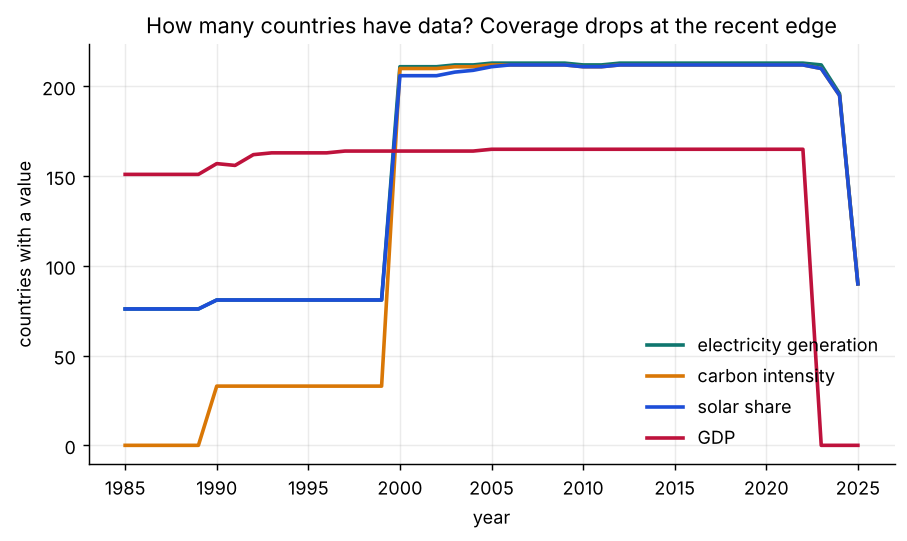

In [2]:
countries, aggregates = cl.split_entities(df)
print(f"{countries['country'].nunique()} countries vs {aggregates['country'].nunique()} aggregates (regions, income groups, 'World', historical entities)")
print("examples of aggregates:", sorted(aggregates['country'].unique())[:6])
n, over, worst = cl.double_count_check(countries, 2024)
print(f"\nAdding the biofuel column to the eight sources would push {over} of {n} countries above 100% (up to {worst:.0f}%): biofuel is already inside 'other renewables'.")
bad = cl.inconsistent_share_rows(countries)
print(f"{len(bad)} country-years have shares that do not sum to 100%, all in {bad['year'].min()}-{bad['year'].max()}.")
display(Image(FIG + "01_coverage.png"))

## 2. The world: shares fall, totals do not
A falling share is not a falling total.

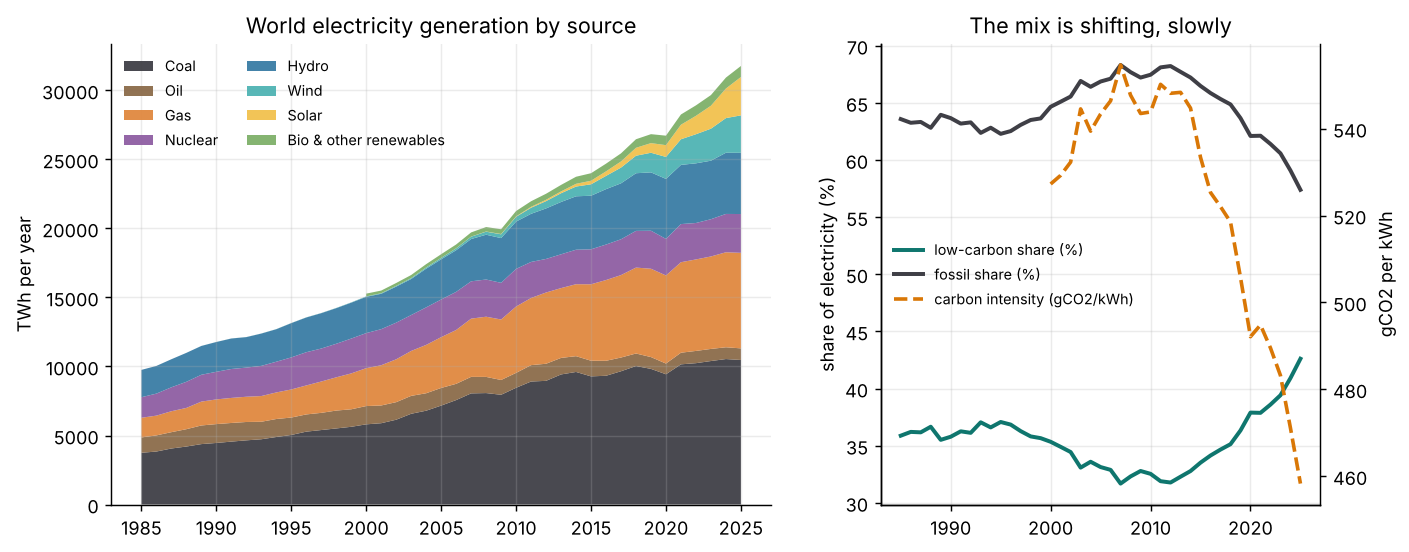

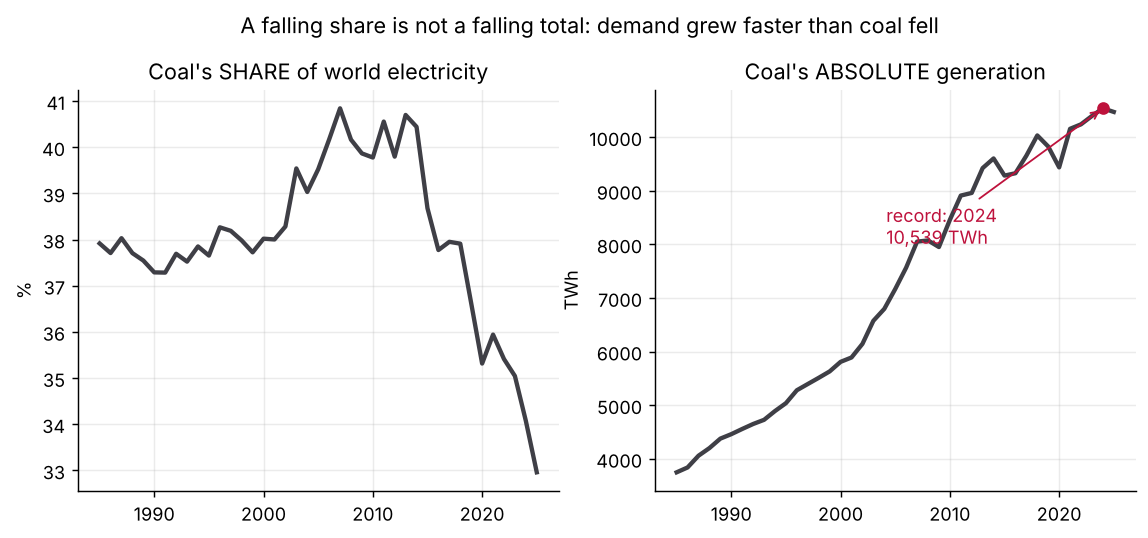

,coal,total,coal_share_elec,low_carbon_share_elec,carbon_intensity_elec
year,,,,,
1990,4460.2,11961.4,37.3,35.8,NaN
2000,5808.8,15278.8,38.0,35.3,527.3
2010,8458.0,21263.8,39.8,32.5,543.9
2014,9603.8,23747.1,40.4,32.8,544.7
2024,10538.9,30930.2,34.1,40.9,471.1


In [3]:
display(Image(FIG + "02_world_mix.png"))
display(Image(FIG + "03_share_vs_absolute.png"))
a.world[["coal", "total", "coal_share_elec", "low_carbon_share_elec", "carbon_intensity_elec"]].loc[[1990, 2000, 2010, 2014, 2024]]

## 3. Who decarbonized between 2014 and 2024?
Low-carbon share = nuclear + hydro + wind + solar + bio/other renewables. Only grids of at least 5 TWh are compared, so tiny systems do not dominate.

,low_carbon_start,low_carbon_end,change_pp
country,,,
Estonia,11.2,55.8,44.6
Lebanon,1.2,43.8,42.7
Netherlands,15.4,53.7,38.2
Belarus,0.8,37.3,36.5
Venezuela,55.9,91.1,35.3
Denmark,56.1,89.2,33.0
Chile,42.8,70.0,27.2
United Kingdom,37.9,64.9,27.0


,low_carbon_start,low_carbon_end,change_pp
country,,,
Tanzania,42.7,32.9,-9.7
Myanmar,63.0,47.9,-15.1
Mozambique,98.7,83.4,-15.2
Laos,100.0,76.7,-23.3
Ghana,63.6,36.2,-27.4


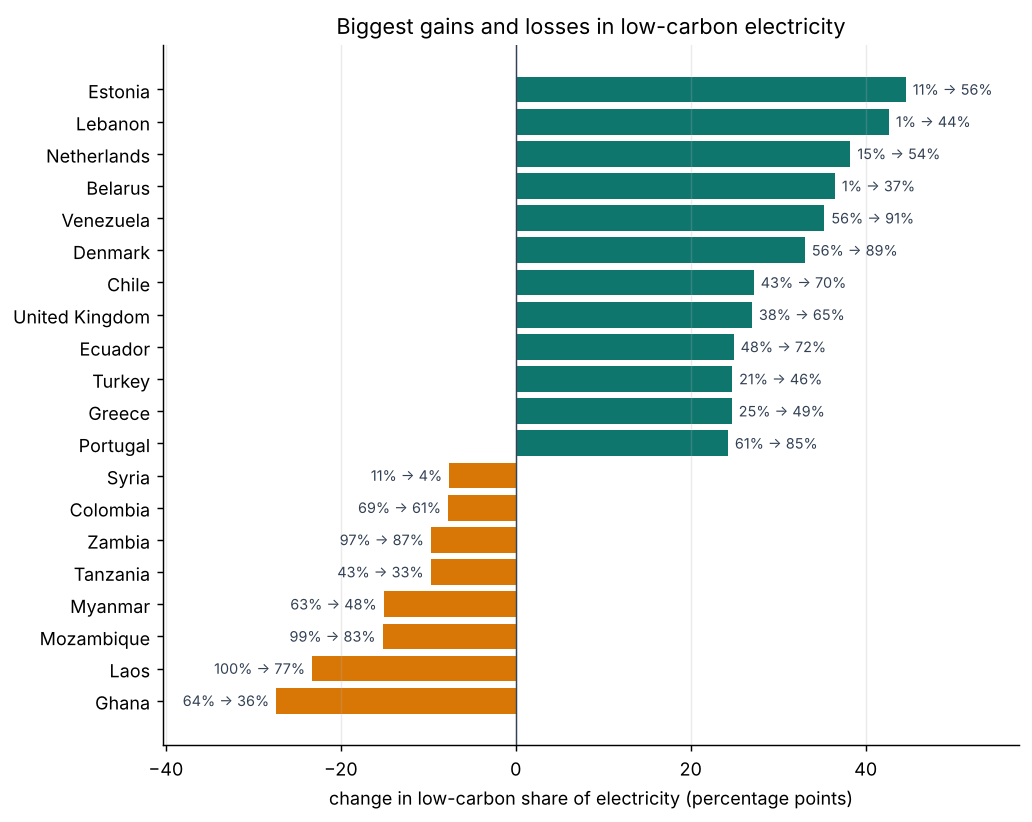

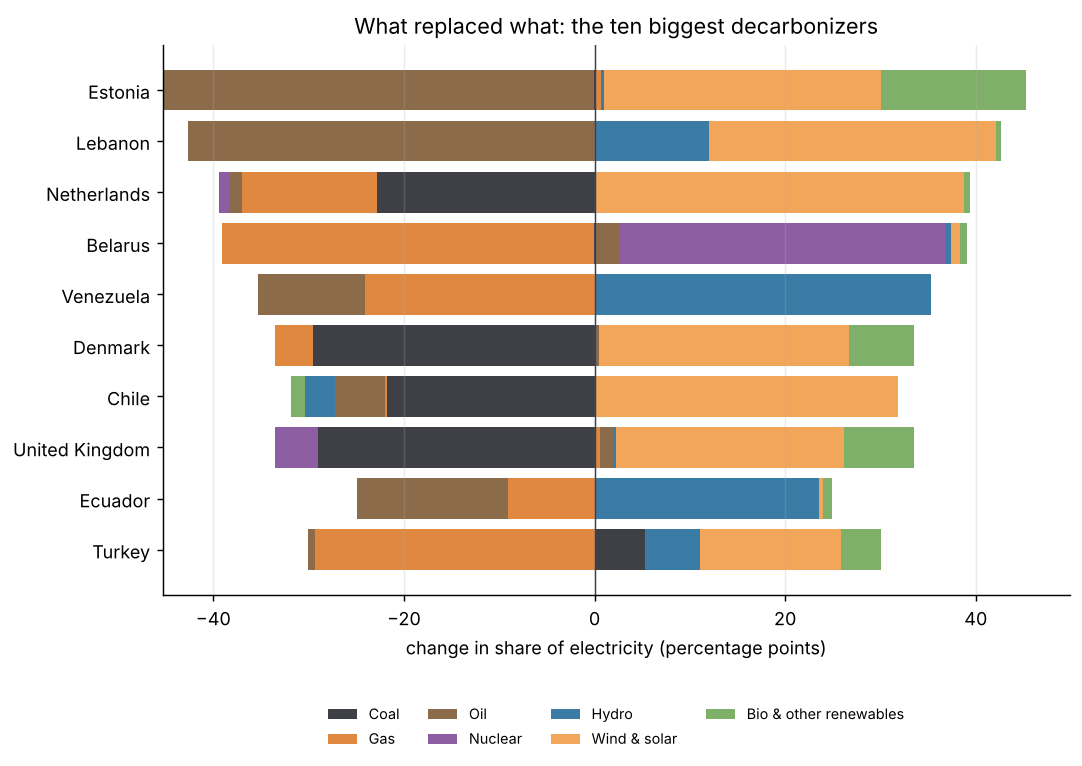

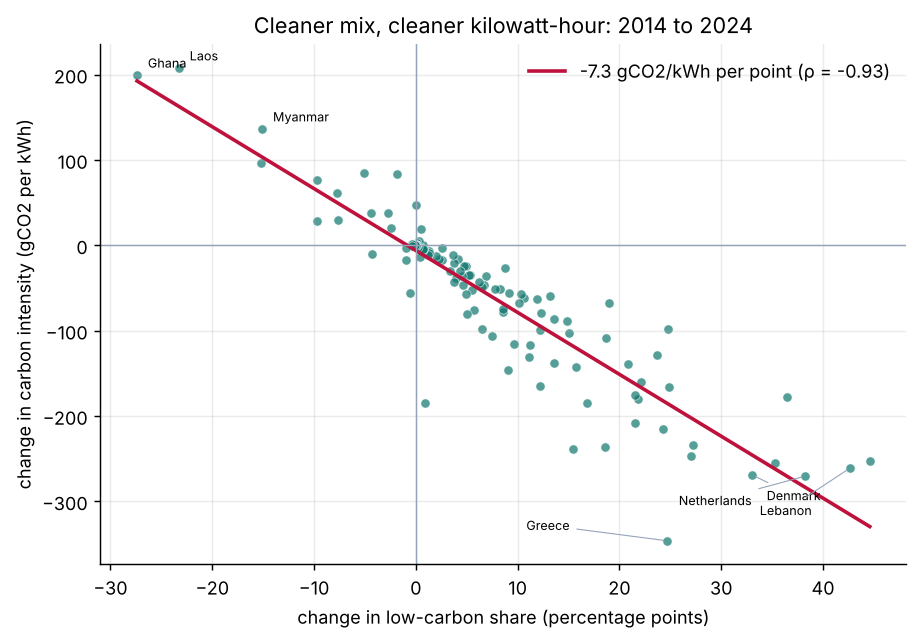

In [4]:
display(a.changes[["low_carbon_start", "low_carbon_end", "change_pp"]].head(8))
display(a.changes[["low_carbon_start", "low_carbon_end", "change_pp"]].tail(5))
display(Image(FIG + "04_leaders_laggards.png"))
display(Image(FIG + "05_what_replaced_what.png"))
display(Image(FIG + "10_carbon_intensity.png"))

## 4. How fast can wind and solar take off?
For each country: years from first reaching 1% to first reaching 10% of electricity. Countries that have not reached 10% yet are *censored*
(we only know they took at least that long), so they are reported separately, not averaged in.

93 grids took off; 57 reached 10%; 36 still on the way
median years from 1% to 10%: 9 (quartiles 5 to 11)


,takeoff_year,years,reached,latest_share,generation_twh
country,,,,,
Democratic Republic of Congo,2021,1,True,15.8,15.9
Lebanon,2021,1,True,30.2,5.3
Jordan,2016,2,True,24.0,23.7
Lithuania,2009,2,True,63.7,8.9
Uzbekistan,2023,2,True,12.1,86.7
Vietnam,2019,2,True,12.1,310.0
Romania,2011,3,True,21.8,49.8
Yemen,2015,3,True,11.2,5.2


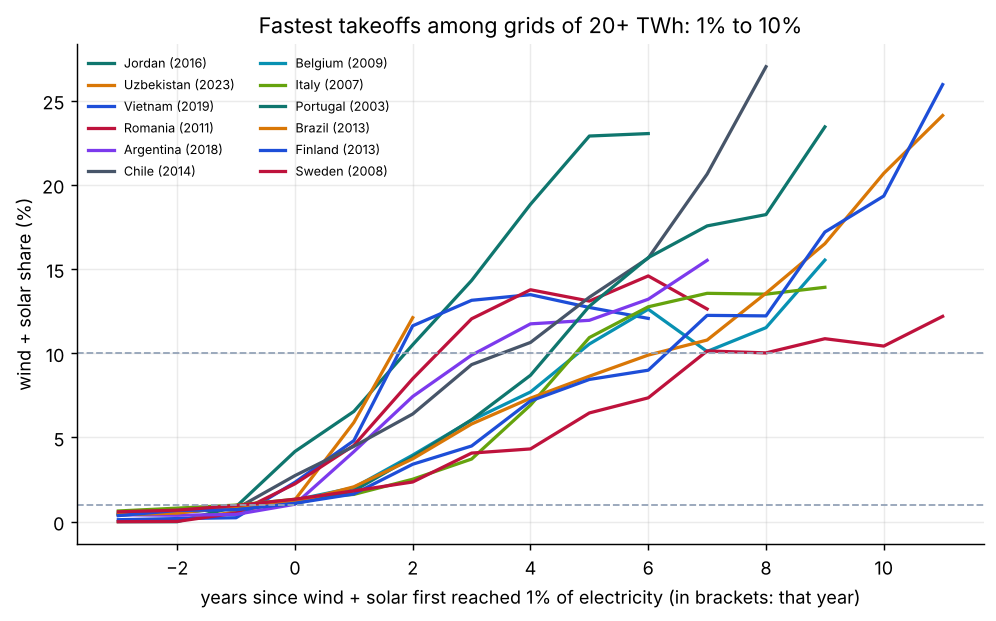

In [5]:
r = a.adoption[a.adoption["reached"]]
print(f"{len(a.adoption)} grids took off; {len(r)} reached 10%; {(~a.adoption['reached']).sum()} still on the way")
print(f"median years from 1% to 10%: {r['years'].median():g} (quartiles {r['years'].quantile(.25):g} to {r['years'].quantile(.75):g})")
display(r.head(8))
display(Image(FIG + "06_adoption_curves.png"))

## 5. Does wealth buy a cleaner grid?
Rank correlations with GDP per person, with bootstrap 95% confidence intervals.

,outcome,rho,ci_low,ci_high,n
0,Low-carbon share of electricity (%),-9.0e-02,-2.5e-01,8.0e-02,145
1,Renewables share (%),-2.1e-01,-3.7e-01,-3.0e-02,145
2,Fossil share (%),9.0e-02,-8.0e-02,2.5e-01,145
3,Carbon intensity (gCO2/kWh),5.0e-02,-1.2e-01,2.1e-01,145
4,Electricity per person (kWh),8.9e-01,8.3e-01,9.3e-01,145


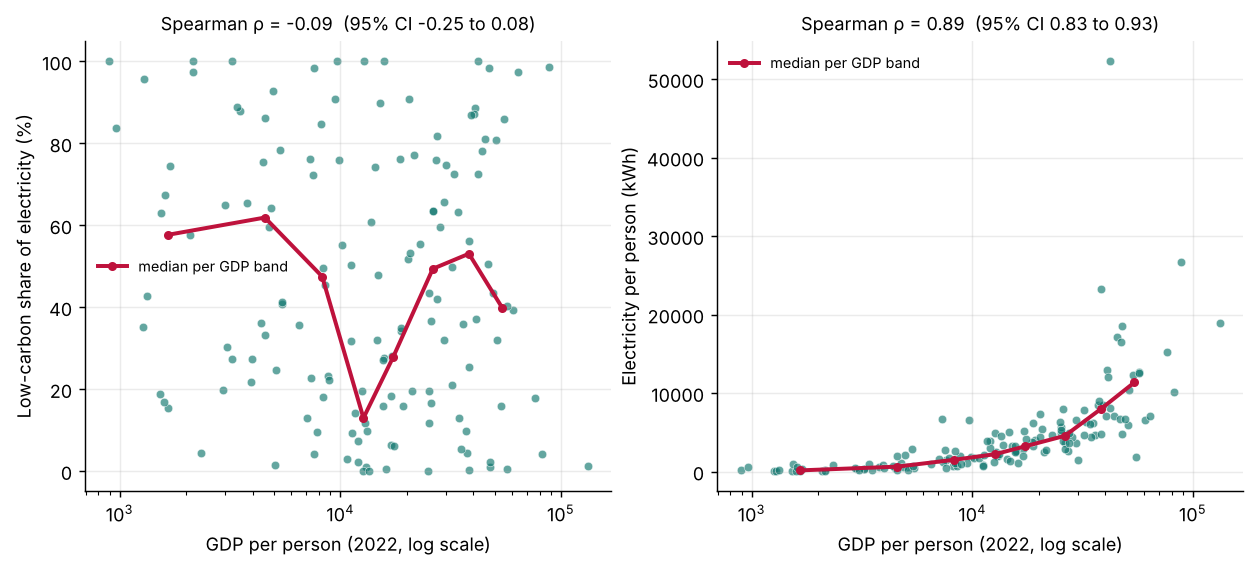

In [6]:
display(a.wealth.round(2))
display(Image(FIG + "07_wealth.png"))

## 6. Electricity archetypes
K-means on the square-root of each country's source shares. *k* is chosen by silhouette among values whose clusters are **stable**
(agreement across random 80% subsamples). All values tried are shown.

,k,silhouette,stability
0,4,0.3,0.9
1,5,0.3,0.8
2,6,0.3,0.8
3,7,0.3,0.7
4,8,0.2,0.7


Hydro-dominated       38 countries, e.g. Brazil, Canada, Norway, Colombia, Venezuela
Gas-dominated         34 countries, e.g. Iran, Mexico, Italy, Egypt, Thailand
Coal-dominated        21 countries, e.g. China, India, Japan, Germany, Indonesia
Nuclear + Gas         20 countries, e.g. United States, Russia, South Korea, France, United Kingdom
Oil-dominated          9 countries, e.g. Puerto Rico, Cuba, Honduras, Senegal, Estonia


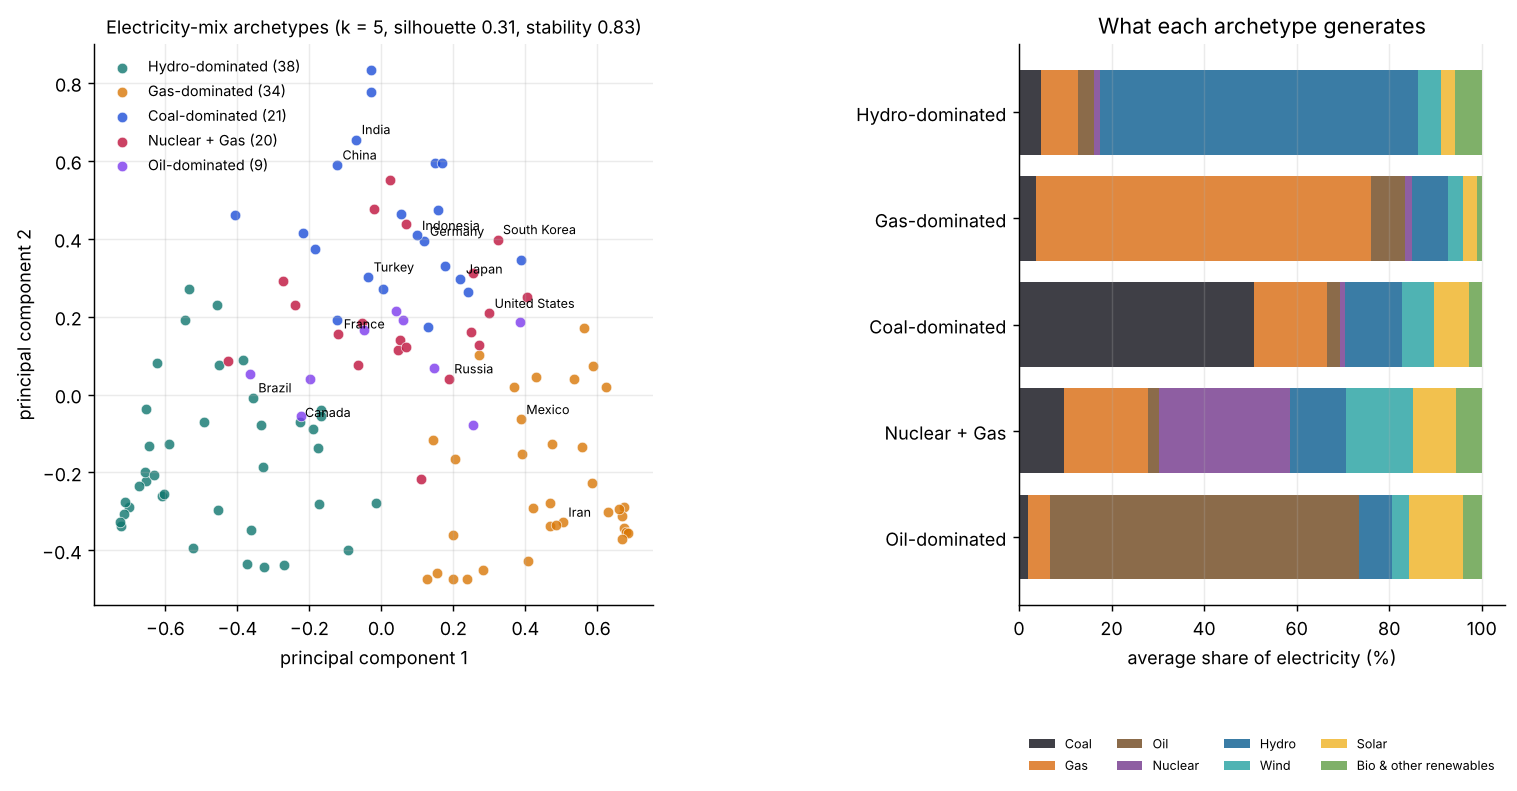

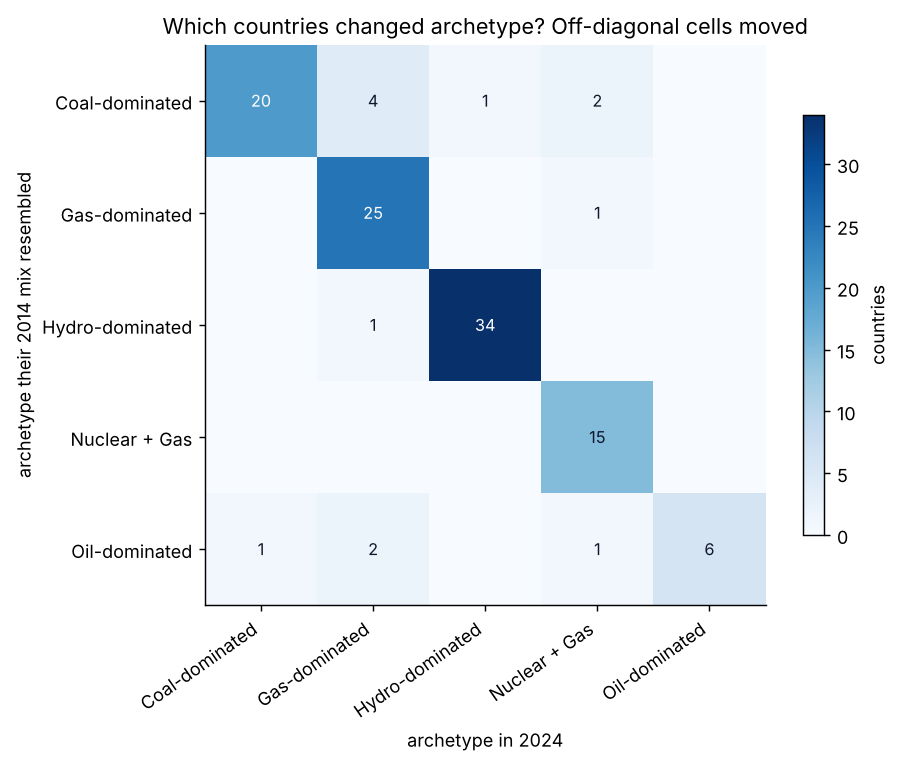

In [7]:
display(a.clusters.scores.round(3))
for cid, name in a.clusters.names.items():
    top = a.mix1.loc[a.clusters.labels[a.clusters.labels == cid].index, "generation_twh"].nlargest(5).index.tolist()
    print(f"{name:20s} {a.clusters.sizes[cid]:3d} countries, e.g. {', '.join(top)}")
display(Image(FIG + "08_archetypes.png"))
display(Image(FIG + "09_transitions.png"))

## 7. Peak coal and a concentrated build-out

,peak_year,peak_twh,latest_twh,decline,past_peak
country,,,,,
Austria,2003,8.0,0.0,1.0,True
Belgium,1990,17.0,0.0,1.0,True
United Arab Emirates,2021,3.0,0.0,1.0,True
Sweden,1996,4.0,0.0,1.0,True
Peru,2012,1.0,0.0,1.0,True
Portugal,2005,15.0,0.0,1.0,True


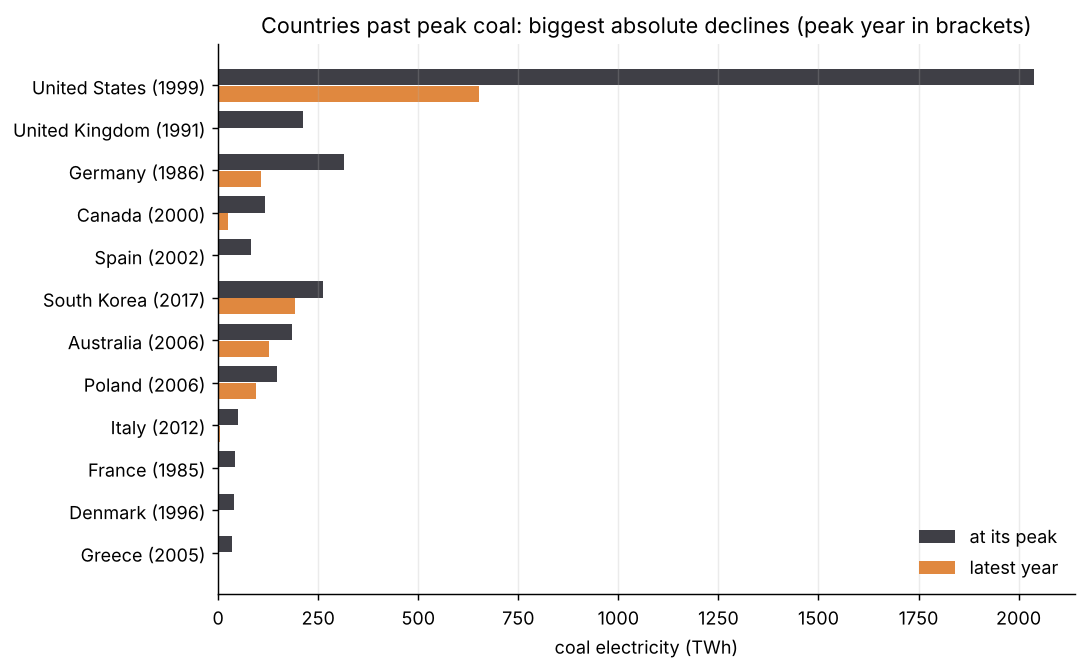

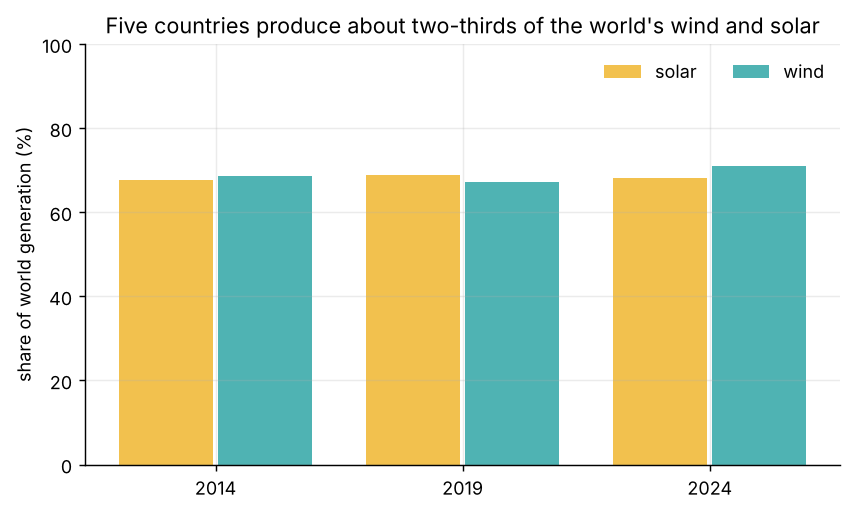

In [8]:
display(a.coal[a.coal["past_peak"]].head(6).round(0))
display(Image(FIG + "11_coal_peaks.png"))
display(Image(FIG + "12_concentration.png"))

## 8. Sensitivity: do the conclusions depend on my choices?
Two checks: the minimum grid size used for rankings, and the number of clusters.

In [9]:
import numpy as np
from sklearn.metrics import adjusted_rand_score
base = set(a.changes.head(10).index)
rows = []
for m in (1, 5, 10, 20):
    ch = an.decarbonization_change(a.countries, 2014, 2024, min_twh=m)
    rows.append({"min grid size (TWh)": m, "countries compared": len(ch), "top-10 overlap with default": len(base & set(ch.head(10).index))})
display(pd.DataFrame(rows))
k5, k6 = an.fit_clusters(a.mix1, k=5, n_boot=5), an.fit_clusters(a.mix1, k=6, n_boot=5)
print(f"agreement between the 5-cluster and 6-cluster solutions (adjusted Rand index): {adjusted_rand_score(k5.labels, k6.labels):.2f}")

,min grid size (TWh),countries compared,top-10 overlap with default
0,1,141,8
1,5,113,10
2,10,92,8
3,20,72,8


agreement between the 5-cluster and 6-cluster solutions (adjusted Rand index): 0.79


## 9. Findings
Generated from the same analysis object, so every number below is computed, not typed.

In [10]:
display(Markdown(report.render_insights(facts)))

# Findings

*Generated from the data by `energy_eda`. Electricity only. Years compared: 2014 and 2024; countries with at least 5 TWh of generation.*

## 1. The world is greening its electricity, but coal is still setting records

- The low-carbon share of world electricity rose from **32.8% to 40.9%** between 2014 and 2024, and wind plus solar from 3.8% to 15.0%.
- Carbon intensity fell from 545 to **471 gCO2 per kWh**.
- Coal's share fell from 40.4% to 34.1%, **yet coal generation hit its record in 2024: 10,539 TWh** (up 9.7% from 9,604 TWh in 2014). Total generation grew 30% over the decade, so coal's output rose even as its share fell.

## 2. Who decarbonized

- Of 113 countries compared, **38 gained 10 or more points** of low-carbon share and **21 went backwards**.
- Biggest gains: Estonia (11.2% → 55.8%); Lebanon (1.2% → 43.8%); Netherlands (15.4% → 53.7%); Belarus (0.8% → 37.3%); Venezuela (55.9% → 91.1%); Denmark (56.1% → 89.2%).
- Biggest losses: Ghana (63.6% → 36.2%); Laos (100.0% → 76.7%); Mozambique (98.7% → 83.4%); Myanmar (63.0% → 47.9%).
- A cleaner mix means a cleaner kilowatt-hour: across 113 countries each extra point of low-carbon share went with **-7.3 gCO2/kWh** (Spearman ρ = -0.93, 95% CI -0.96 to -0.88).

## 3. How fast can a new source take off

- 93 grids of meaningful size moved wind plus solar past 1% of their electricity; 57 have since passed 10% (the rest are still on the way). The median time from 1% to 10% was **9 years** (middle half: 5 to 11).
- Later starters look quicker: takeoffs since 2015 reached 10% in a median **3.5 years** (n = 12), against 12 years for takeoffs before 2010 (n = 21). Recent takeoffs are, by construction, still being observed, so the recent figure only counts the fast ones.

## 4. Wealth does not buy a clean grid

- Across countries in 2022, GDP per person shows no clear relationship with the low-carbon share of electricity (Spearman ρ = -0.09, 95% CI -0.25 to 0.08), but a strong one with how much electricity each person uses (ρ = 0.89).
- Among the richest quarter of countries (37 of them) the low-carbon share ranges from 2% to 92% (10th to 90th percentile): wealth explains *how much* electricity a country uses, not *how clean* it is.

## 5. Country archetypes

- Clustering the 2024 electricity mixes gives **5 archetypes** (silhouette 0.312, stability 0.83; stability is the average agreement between clusterings of random 80% subsamples, 1 = identical).
  - **Hydro-dominated**: 38 countries, including Brazil, Canada, Norway, Colombia.
  - **Gas-dominated**: 34 countries, including Iran, Mexico, Italy, Egypt.
  - **Coal-dominated**: 21 countries, including China, India, Japan, Germany.
  - **Nuclear + Gas**: 20 countries, including United States, Russia, South Korea, France.
  - **Oil-dominated**: 9 countries, including Puerto Rico, Cuba, Honduras, Senegal.
- The archetype that leans most on wind and solar is **Nuclear + Gas** (about 24% of its electricity on average): the most diversified group, not a separate 'renewables' cluster.
- Re-assigning each country's 2014 mix to today's archetypes, **13 of 113 countries** now sit in a different archetype.

## 6. Peak coal

- 43 of 76 coal-using countries now generate at least 25% less coal power than at their peak, **29 of them peaking before 2015**.
- Largest declines: United States (2,038 TWh in 1999 → 652 TWh); United Kingdom (211 TWh in 1991 → 2 TWh); Germany (315 TWh in 1986 → 106 TWh); Canada (116 TWh in 2000 → 25 TWh).

## 7. A concentrated build-out

- Five countries (China, United States, India, Japan, Germany) produced **68% of the world's solar electricity** in 2024. The share was 68% in 2014 too, but with a different line-up (Germany, United States, Japan, China, Italy). For wind the top five (China, United States, Germany, Brazil, United Kingdom) produced 71%.

## Data-quality notes

- The file has 23,377 rows for 314 entities, but only **220 are countries**; the other 94 are regions, income groups or historical entities and must be excluded from rankings.
- Adding the separate biofuel column to the eight source shares double-counts biofuel (it is already inside `other_renewables`): shares exceeded 100% for **73 of 122 countries** in 2024 (up to 122.4%).
- 107 country-year rows have shares not summing to 100%, all between 1985 and 1999.
- Coverage thins at the recent edge: 196 countries have 2024 electricity data but only 90 have 2025, and GDP stops at 2022 (165 countries in 2022). That is why the analysis ends at 2024 and the wealth comparison uses 2022.

## Caveats

- This is about **electricity**, not total energy: transport, heating and industry are not covered.
- Shares describe where electricity is generated, not where it is consumed; cross-border trade is ignored.
- Correlations are descriptive. They show which countries are alike, not what caused a change.
- Cluster names come from each cluster's dominant sources; neighbouring clusters overlap and a few countries sit near the boundary.
- Tiny grids are excluded by the minimum-size rule, and results depend on it (see the sensitivity checks in the notebook).
